In [21]:
import os
from dotenv import load_dotenv
load_dotenv()

GROQ_API_KEY=os.getenv('GROQ_API_KEY')

In [22]:
from typing import TypedDict , Union , List , Annotated , Sequence 

from langchain_core.messages import BaseMessage
from langchain_core.messages import ToolMessage
from langchain_core.messages import SystemMessage 
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage , AIMessage

from langgraph.graph import StateGraph , START , END
from langgraph.prebuilt import ToolNode
from langgraph.graph.message import add_messages
from langchain_core.tools import tool

In [23]:
# adds additional information

email = Annotated[str , 'This has to be a valid email address']
email.__metadata__


# Sequence # automatically handles the state message

('This has to be a valid email address',)

In [24]:
# reducer function
# updates the new values to the current state
# without this -> it would have replace the existing state


In [39]:
class AgentState(TypedDict):
    messages : Annotated[Sequence[BaseMessage], add_messages]
    
    
model = ChatGroq(model="openai/gpt-oss-120b")


In [40]:
@tool 
def add(a : int , b : int) : 
    """
    This is an Addition function that adds 2 numbers
    """
    return a + b

tools = [add]

In [41]:
model.bind_tools(tools)

RunnableBinding(bound=ChatGroq(client=<groq.resources.chat.completions.Completions object at 0x000001F0912E39E0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F0912E1070>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'add', 'description': 'This is an Addition function that adds 2 numbers', 'parameters': {'properties': {'a': {'type': 'integer'}, 'b': {'type': 'integer'}}, 'required': ['a', 'b'], 'type': 'object'}}}]}, config={}, config_factories=[])

In [48]:
def model_call(state: AgentState) :
    system_prompt = SystemMessage(
        content = 'you are my Excellent AI assistant , please answer my query to the best of your ability '
    )
    response = model.invoke([system_prompt] + state['messages']) 
    return {'messages': [response]}  

In [54]:
def should_continue(state : AgentState):
    messages = state['messages']
    if not messages[-1].tool_calls :
        return "end"
    else :
        return "continue"

In [55]:
graph = StateGraph(AgentState)
graph.add_node('our_agent', model_call)


tool_node = ToolNode(tools = tools)
graph.add_node('tools', tool_node)

graph.set_entry_point('our_agent')

graph.add_conditional_edges('our_agent',should_continue,
        {
            'continue':'tools',
            'end':END
        }                        
)
graph.add_edge('tools','our_agent')

app = graph.compile()

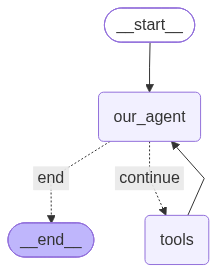

In [56]:
app

In [57]:
def print_stream(stream):
    for s in stream:
        message = s["messages"][-1]
        if isinstance(message, tuple): 
            print(message)
        else:
            message.pretty_print()

In [60]:
inputs = {"messages": [("user", "Add 31 + 4. Add 1 + 1  Add 1 + 2")]}
print_stream(app.stream(inputs, stream_mode="values"))

================================ Human Message =================================

Add 31 + 4. Add 1 + 1  Add 1 + 2
================================== Ai Message ==================================

Sure! Here are the results:

- **31 + 4 = 35**  
- **1 + 1 = 2**  
- **1 + 2 = 3**
